In [1]:
!pip install google-play-scraper Sastrawi catboost

In [2]:
# from google_play_scraper import reviews, Sort, app as get_app_info
import pandas as pd
import json
import re
import nltk
import sklearn
from nltk.tokenize import word_tokenize
import unicodedata
from sklearn.feature_extraction.text import TfidfVectorizer
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import numpy as np
import os

<h1>Scraping Data</h1>

In [3]:
# app_id = "com.telkomsel.telkomselcm"
# jumlah_ulasan = 500
# tahun = 2026

In [4]:
# info = get_app_info(app_id, lang="id", country="id")
# hasil, _ = reviews(
#     app_id,
#     lang='id',  # Bahasa Indonesia
#     country='id',  # Indonesia
#     sort=Sort.NEWEST,  # Mengambil ulasan terbaru
#     count=jumlah_ulasan,  # Jumlah ulasan yang diambil
# )

In [5]:
# df_raw = pd.DataFrame(hasil)[["reviewId", "userName", "content", "score", "at", "reviewCreatedVersion"]]
# df_raw.columns = ["id_ulasan", "nama_pengguna", "ulasan", "rating", "tanggal", "versi_aplikasi_ulasan"]
# df_raw["tanggal"] = pd.to_datetime(df_raw["tanggal"])

In [6]:
# df = df_raw[df_raw['tanggal'].dt.year == tahun].copy()

In [7]:
# nama_file = f"ulasan_mytelkom_{tahun}.csv"
# df.to_csv(nama_file, index=False, encoding='utf-8-sig')

<h1>Data Load</h1>

In [8]:
SHEET_ID = "1JVpzO2-EAivK-HwRGoiLHcOTJWzX94UV1T1y1Xz-7Jg"
GID = "1412720530"
URL_SHEET = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"
df = pd.read_csv(URL_SHEET)
df["ulasan"] = df["ulasan"].fillna("").astype(str)   # avoid errors on empty reviews
df.to_csv("ulasan_mytelkom_2026.csv", index=False, encoding="utf-8-sig")
print(f"Loaded {len(df)} rows")
print(df.columns.tolist())
df.head()

Loaded 500 rows
['id_ulasan', 'nama_pengguna', 'ulasan', 'rating', 'tanggal', 'versi_aplikasi_ulasan', 'Bagus', 'Daniel', 'Liza', 'Cila', 'Missy', 'Summary']


,id_ulasan,nama_pengguna,ulasan,rating,tanggal,versi_aplikasi_ulasan,Bagus,Daniel,Liza,Cila,Missy,Summary
0,c0189ec1-51f2-4d64-a974-a23f6e953702,Rizaldy Rais,jaringan Telkomsel wilayah Agam timur sangat l...,1,2026-09-17 12:47:48,9.3.2000,negative,negative,negative,negative,negative,negative
1,32c878a1-25c9-46c8-a645-a506f422f236,Darwin Ipin,mantap,5,2026-09-17 12:46:36,9.3.2000,positive,positive,positive,positive,positive,positive
2,46728e9d-95a0-42cc-a3d7-79727e140e24,Endang Setiasih,Suka kluar sendiri padahal hp ram 8 aneh nih a...,1,2026-09-17 12:46:30,9.3.2000,negative,negative,negative,negative,negative,negative
3,3a761f28-8040-4395-ba2f-a44f6f8c41b6,Randi Priyanto,maaf ya saya kurangin dulu bintang nya soal ny...,3,2026-09-17 12:46:28,8.6.2002,negative,negative,negative,negative,negative,negative
4,80a08cf2-7248-4efa-9016-95681b423214,eko z,sinyal lemot sering keluar aplikasi sendiri ma...,1,2026-09-17 12:45:37,9.2.2001,negative,negative,negative,negative,negative,negative


<h1>Tokenize</h1>

In [9]:
INPUT_PATH = "ulasan_mytelkom_2026.csv"
OUTPUT_PATH = "ulasan_tokenized_nltk.json"
nltk.download("punkt")
nltk.download("punkt_tab")
ANGKA = {"satu": "1", "dua": "2", "tiga": "3", "empat": "4", "lima": "5"}
def gabung_bintang(teks):
    pola_angka = r"(satu|dua|tiga|empat|lima|[1-5])"
    teks = re.sub(rf"\b{pola_angka}\s*bintang\b",lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    teks = re.sub(rf"\bbintang\s*{pola_angka}\b",lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    return teks

def tokenize(teks):
    teks = str(teks).lower()
    teks = gabung_bintang(teks)
    for tanda in [".", ",", ";", ":", "?", "!"]:
        teks = teks.replace(tanda, " ")
    return word_tokenize(teks)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [10]:
df = pd.read_csv(INPUT_PATH)
df["ulasan"] = df["ulasan"].fillna("").astype(str)
df["tokens"] = df["ulasan"].apply(tokenize)
df.to_json(OUTPUT_PATH, orient="records", force_ascii=False, indent=2)
print(f"NLTK tokenize DONE: {OUTPUT_PATH}")

NLTK tokenize DONE: ulasan_tokenized_nltk.json


<h1>Normalization</h1>

In [11]:
INPUT_PATH_NORM = "ulasan_tokenized_nltk.json"
OUTPUT_PATH_NORM = "ulasan_normalized.json"

In [12]:
URL_KAMUS = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"

try:
    df_kamus = pd.read_csv(URL_KAMUS).dropna(subset=["slang", "formal"])
    kamus_slang = dict(zip(
        df_kamus["slang"].astype(str).str.lower().str.strip(),
        df_kamus["formal"].astype(str).str.lower().str.strip()
    ))
    print(f"Kamus alay dimuat: {len(kamus_slang)} entri")
except Exception as e:
    kamus_slang = {}
    print(f"Gagal memuat kamus online ({e}), pakai kamus manual saja")

Kamus alay dimuat: 4330 entri


In [13]:
kamus_manual = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "ngak": "tidak", "nggak": "tidak", "tdk": "tidak",
    "yg": "yang", "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "belom": "belum",
    "bgt": "banget", "sy": "saya", "aq": "aku", "gw": "saya", "gue": "saya",
    "dgn": "dengan", "dg": "dengan", "utk": "untuk", "tp": "tapi", "krn": "karena", "karna": "karena",
    "trs": "terus", "jd": "jadi", "jg": "juga", "lg": "lagi", "bs": "bisa", "bsa": "bisa", "sm": "sama",
    "knp": "kenapa", "gmn": "bagaimana", "gimana": "bagaimana", "kalo": "kalau", "klo": "kalau",
    "dr": "dari", "org": "orang", "hrs": "harus", "msh": "masih", "aja": "saja", "aj": "saja",
    "pake": "pakai", "pakek": "pakai",
    "apk": "aplikasi", "app": "aplikasi", "apl": "aplikasi", "tsel": "telkomsel",
    "kouta": "kuota", "qouta": "kuota", "signal": "sinyal", "singnal": "sinyal",
    "min": "admin", "mimin": "admin",
    "gpp": "tidak apa apa", "gapapa": "tidak apa apa", "mantul": "mantap betul",
    "makasih": "terima kasih", "mksh": "terima kasih", "trims": "terima kasih", "thx": "terima kasih", "tq": "terima kasih",
    "ok": "oke", "okay": "oke", "bgs": "bagus", "lemot": "lambat", "lelet": "lambat",
    "erorr": "error"
}
kamus_manual.update({"pket":"paket","eror":"error","ngetod":"ngentod","taaiiiiiiii":"tahi","pol":"banget","pelitt":"pelit","anjig":"anjing","pukii":"puki","provder":"provider","njingg":"anjing"
,"berberapa":"beberapa","loadingnya":"loading","bitang":"bintang","sangtlah":"sangat","semuaa":"semua","jaringannya":"jaringan","indihomenya":"indihome","ajg":"anjing","relog":"login","sebeluh":"sebelah","kont0l":"kontol","byar":"bayar","fix":"perbaiki","mausuk":"masuk",
"mahalin":"mahal","stbill":"stabil","anying":"anjing","gbsa":"tidak","desedot":"disedot","gblok":"goblok","bug":"masalah","mura":"murah","mkasih":"terima kasih","lag":"lambat","samsek":"sama sekali"})
kamus_manual.update({
    "enggak": "tidak", "engga": "tidak", "ngga": "tidak", "nggak": "tidak", "kagak": "tidak", "kaga": "tidak", "engak": "tidak",
    "gajelas": "tidak jelas", "gabisa": "tidak bisa", "gada": "tidak ada", "gaada": "tidak ada", "gamau": "tidak mau", "gapernah": "tidak pernah",
    "mb": "mb", "gb": "gb", # Override "mb" in case it was mapped to "mbak"
    "kelemotan": "lambat", "lemotnya": "lambat", "lemoth": "lambat",
    "kuoto": "kuota", "membatu": "membantu", "memuaskn": "memuaskan", "bsgus": "bagus", "sangst": "sangat",
})
kamus_normalisasi = {**kamus_slang, **kamus_manual}
print(f"Total kamus normalisasi: {len(kamus_normalisasi)} entri")

Total kamus normalisasi: 4397 entri


In [14]:
kamus_emoji = {
    "👍": " bagus ", "👎": " jelek ", "🥰": " suka ", "😍": " suka ", "❤": " suka ",
    "🙏": " terima kasih ", "😡": " marah ", "🤬": " marah ", "😭": " sedih ",
    "😞": " kecewa ", "🤢": " jijik ",
    "🙄": " kesal ", "😤": " kesal ", "😠": " marah ", "😢": " sedih ", "💩": " jelek ",
    "😊": " senang ", "😁": " senang ", "🔥": " mantap ", "💯": " mantap ",
    # 😂 sengaja tidak dipetakan: di ulasan keluhan sering dipakai untuk sarkasme
}
print(f"Kamus emoji dimuat: {len(kamus_emoji)} entri")

Kamus emoji dimuat: 20 entri


In [15]:
df_tokenized = pd.read_json(INPUT_PATH_NORM, orient="records")
def normalize_token(tokens):
    normalized_tokens_list = []
    for token in tokens:
        token = unicodedata.normalize("NFKC", token).lower()
        for emoji_char, replacement_word in kamus_emoji.items():
            token = token.replace(emoji_char, replacement_word)
        token = re.sub(r'http\S+|www\S+', '', token)
        token = token.replace('-', ' ')
        token = re.sub(r'[^a-z0-9_\s]', ' ', token)
        token = re.sub(r'\s+', ' ', token).strip()
        token = re.sub(r'([a-z])\1{2,}', r'\1', token)
        sub_tokens = token.split()
        processed_sub_tokens = []
        for sub_token in sub_tokens:
            match_repeated_word = re.match(r'([a-z]{2,})2$', sub_token)
            if match_repeated_word:
                base_word = match_repeated_word.group(1)
                processed_sub_tokens.extend([base_word, base_word])
                continue
            first_normalized = kamus_normalisasi.get(sub_token, sub_token)
            for part in first_normalized.split():
                processed_sub_tokens.append(kamus_normalisasi.get(part, part))
        normalized_tokens_list.extend([t for t in processed_sub_tokens if t])
    return normalized_tokens_list
df_tokenized["tokens_asli"] = df_tokenized["tokens"]
df_tokenized["tokens"] = df_tokenized["tokens"].apply(normalize_token)
df_tokenized.to_json(OUTPUT_PATH_NORM, orient="records", force_ascii=False, indent=2)
print(f"Normalization DONE: {OUTPUT_PATH_NORM}")

Normalization DONE: ulasan_normalized.json


<h1>Stopword</h1>

In [16]:
INPUT_PATH_STOPWORD = "ulasan_normalized.json"
OUTPUT_PATH_STOPWORD = "ulasan_filtered.json"

In [17]:
factory = StopWordRemoverFactory()
stopwords_sastrawi = factory.get_stop_words()

In [18]:
stopwords_sastrawi = set(stopwords_sastrawi)
stopwords_sastrawi -= {"tidak", "belum", "bukan", "jangan","bisa", "tapi", "namun", "tanpa", "tolong","dapat", "harus", "masih", "hanya", "agak"}

In [19]:
if not os.path.exists(INPUT_PATH_STOPWORD):
    raise FileNotFoundError(f"Error: File '{INPUT_PATH_STOPWORD}' not found. Please ensure normalization is done and the file exists.")
with open(INPUT_PATH_STOPWORD, "r", encoding="utf-8") as f:
    data_ulasan = json.load(f)
for item in data_ulasan:
    if "tokens" in item:
        tokens_awal = item["tokens"]
        tokens_bersih = [kata for kata in tokens_awal if kata.lower() not in stopwords_sastrawi]
        item["filtered_tokens"] = tokens_bersih
with open(OUTPUT_PATH_STOPWORD, "w", encoding="utf-8") as f:
    json.dump(data_ulasan, f, ensure_ascii=False, indent=2)
print(f"stopword DONE: {OUTPUT_PATH_STOPWORD}")

stopword DONE: ulasan_filtered.json


<h1>Stemming</h1>

In [20]:
INPUT_PATH_FILTERED = "ulasan_filtered.json"
OUTPUT_PATH_FILTERED = "ulasan_Clean.json"

In [21]:
with open(INPUT_PATH_FILTERED, "r", encoding="utf-8") as f:
    data = json.load(f)
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [22]:
stem_cache = {}
stem_manual = {
    "berikan": "beri", "kurangin": "kurang", "pengecekan": "cek",
    "sebelumnya": "sebelum", "perusahan": "perusahaan", "perusahaan": "perusahaan",
    "bekasi": "bekasi", "bali": "bali", "maluku": "maluku",
}
def get_token_key(item):
    for key in ["filtered_tokens", "tokens_filtered", "tokens"]:
        if key in item:
            return key
    raise KeyError(f"Key token tidak ditemukan: {list(item.keys())}")
def stem_word(word):
    if word in stem_manual:
        return stem_manual[word]
    if "_" in word or any(ch.isdigit() for ch in word):
        return word
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

In [23]:
if "stem_cache" not in globals():
    stem_cache = {}

cleaned_data = []
for item in data:
    token_key = get_token_key(item)
    stemmed = [s for s in (stem_word(t) for t in item[token_key]) if s.strip()]
    cleaned_data.append({
        **{k: v for k, v in item.items() if k != token_key},
        "tokens_stemmed": stemmed,
        "ulasan_clean": " ".join(stemmed),
    })

In [24]:
with open(OUTPUT_PATH_FILTERED, "w", encoding="utf-8") as f:
    json.dump(cleaned_data, f, ensure_ascii=False, indent=2)

<h1>Imbalance Analysis</h1>

In [25]:
target = pd.DataFrame(cleaned_data)
target["ulasan_clean"] = target["ulasan_clean"].fillna("").astype(str)
kosong = target["ulasan_clean"].str.strip() == ""
print(f"Ulasan kosong dibuang: {kosong.sum()}")
target = target[~kosong].reset_index(drop=True)
label_map = {"negative": -1, "neutral": 0, "positive": 1}
print(target["Summary"].value_counts(dropna=False))
target["target"] = target["Summary"].astype(str).str.strip().str.lower().map(label_map)
print(f"Baris tanpa label valid dibuang: {target["target"].isna().sum()}")
target = target.dropna(subset=["target"]).reset_index(drop=True)
target["target"] = target["target"].astype(int)
print(f"Jumlah data untuk model: {len(target)}")

Ulasan kosong dibuang: 0
Summary
negative    353
positive     96
neutral      51
Name: count, dtype: int64
Baris tanpa label valid dibuang: 0
Jumlah data untuk model: 500


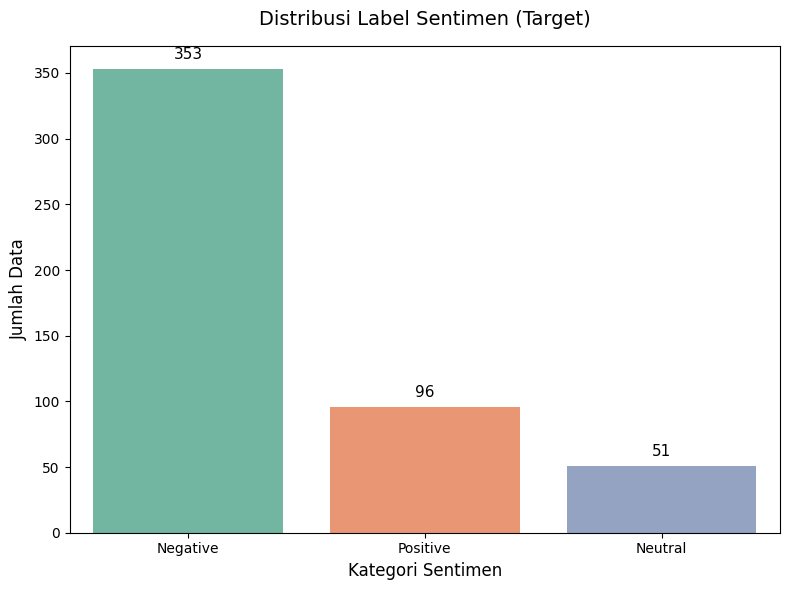

In [26]:
plt.figure(figsize=(8, 6))
kategori_counts = target["Summary"].str.strip().str.title().value_counts()
ax = sns.barplot(x=kategori_counts.index, y=kategori_counts.values, hue=kategori_counts.index, palette="Set2", legend=False)
plt.title("Distribusi Label Sentimen (Target)", fontsize=14, pad=15)
plt.xlabel("Kategori Sentimen", fontsize=12)
plt.ylabel("Jumlah Data", fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),ha='center', va='bottom', fontsize=11, color='black',xytext=(0, 5),textcoords='offset points')
plt.tight_layout()
plt.show()

<h3>Fleis-Kappa Analysis</h3>

In [27]:
df_label = pd.DataFrame(cleaned_data)
anotator = [c for c in ["Bagus", "Daniel", "Liza", "Cila", "Missy"] if c in df_label.columns]
lab = df_label[anotator].apply(lambda s: s.astype(str).str.strip().str.lower().map(label_map))
lab = lab.dropna().astype(int)
if len(anotator) >= 2 and len(lab) > 0:
    tabel, _ = aggregate_raters(lab.values)
    print(f"Fleiss' kappa ({len(anotator)} anotator, {len(lab)} ulasan): {fleiss_kappa(tabel):.4f}")
else:
    print("Kolom anotator tidak ditemukan atau labelnya tidak cocok dengan negative/neutral/positive.")

Fleiss' kappa (5 anotator, 500 ulasan): 0.8751


<h1>Train-Test Split</h1>

In [28]:
teks = target["ulasan_clean"]
y = target["target"]

teks_train_full, teks_test, y_train_full, y_test = train_test_split(
    teks, y, test_size=0.2, random_state=42, stratify=y
)
teks_train, teks_val, y_train, y_val = train_test_split(
    teks_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)
print(f"train: {len(teks_train)} | val: {len(teks_val)} | test: {len(teks_test)}")

train: 340 | val: 60 | test: 100


<h1>Vectorization</h1>

<h3>TF-IDF Vectorization</h3>

In [29]:
# TF-IDF di-fit hanya pada data train. Bigram menjaga frasa seperti "tidak bagus".
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(teks_train).toarray()
X_val = vectorizer.transform(teks_val).toarray()
X_test = vectorizer.transform(teks_test).toarray()

print(X_train.shape, X_val.shape, X_test.shape)
print(vectorizer.get_feature_names_out()[:50])

(340, 728) (60, 728) (100, 728)
['10' '100' '11' '16' '188' '23' '28' '28 hari' '30' '30 hari' '3gb' '4g'
 '5g' '60' 'ada' 'admin' 'aduh' 'agak' 'akal' 'akhir' 'akses' 'aktif'
 'aktif paket' 'aktivitas' 'aku' 'aku beli' 'akun' 'akun sendiri' 'alas'
 'ampun' 'anak' 'aneh' 'anjing' 'anti' 'anti spam' 'apa' 'apa bagaimana'
 'apa coba' 'apa sih' 'apa telkomsel' 'aplikasi' 'aplikasi bayar'
 'aplikasi berat' 'aplikasi bisa' 'aplikasi buat' 'aplikasi buruk'
 'aplikasi error' 'aplikasi kalau' 'aplikasi lambat' 'aplikasi nya']


<h3>Bert Embedding Vectorization</h3>

In [30]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModel
model_name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

def get_indobert_embeddings(text_list, batch_size=16):
    model.eval()
    embeddings = []

    for i in range(0, len(text_list), batch_size):
        batch_texts = text_list[i:i+batch_size]
        encoded_input = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            output = model(**encoded_input)
            cls_embedding = output.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())

    return np.vstack(embeddings)
teks_train_list = list(teks_train)
teks_val_list = list(teks_val)
teks_test_list = list(teks_test)

X_train_bert = get_indobert_embeddings(teks_train_list)
X_val_bert = get_indobert_embeddings(teks_val_list)
X_test_bert = get_indobert_embeddings(teks_test_list)

print(X_train_bert.shape, X_val_bert.shape, X_test_bert.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(340, 768) (60, 768) (100, 768)


<h3>Imbalance Handling With Class-Weight</h3>

In [31]:
classes = np.array([-1, 0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))
print("Class weights:", class_weights)

Class weights: {np.int64(-1): np.float64(0.4722222222222222), np.int64(0): np.float64(3.238095238095238), np.int64(1): np.float64(1.7435897435897436)}


<h1>Modelling With Class-Weight</h1>

<h3>TF-IDF</h3>

In [32]:
#Catboost

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    class_weights=class_weights,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train,y_train,eval_set=(X_val, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test).ravel()

0:	learn: 1.0673560	test: 1.0692548	best: 1.0692548 (0)	total: 62.4ms	remaining: 31.1s
100:	learn: 0.3972722	test: 0.5419088	best: 0.5419088 (100)	total: 946ms	remaining: 3.74s
200:	learn: 0.2883152	test: 0.4899969	best: 0.4899969 (200)	total: 1.78s	remaining: 2.65s
300:	learn: 0.2353609	test: 0.4718792	best: 0.4716724 (299)	total: 2.62s	remaining: 1.74s
400:	learn: 0.2036464	test: 0.4588821	best: 0.4588821 (400)	total: 3.45s	remaining: 852ms
499:	learn: 0.1801371	test: 0.4478369	best: 0.4466746 (483)	total: 4.26s	remaining: 0us
bestTest = 0.4466745921
bestIteration = 483
Shrink model to first 484 iterations.


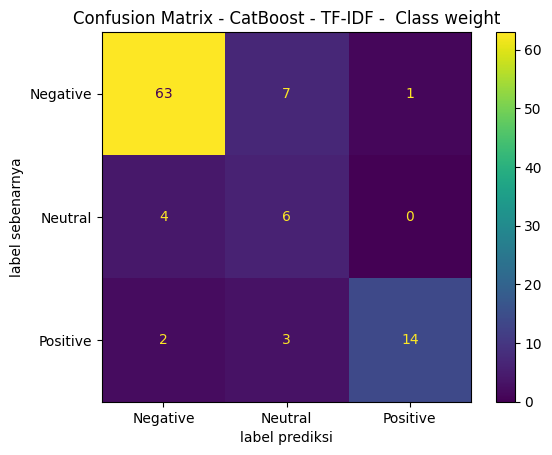

In [33]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - TF-IDF -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [34]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9130    0.8873    0.9000        71
     Neutral     0.3750    0.6000    0.4615        10
    Positive     0.9333    0.7368    0.8235        19

    accuracy                         0.8300       100
   macro avg     0.7405    0.7414    0.7284       100
weighted avg     0.8631    0.8300    0.8416       100



In [35]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000)

In [36]:
y_pred = lr.predict(X_test).ravel()

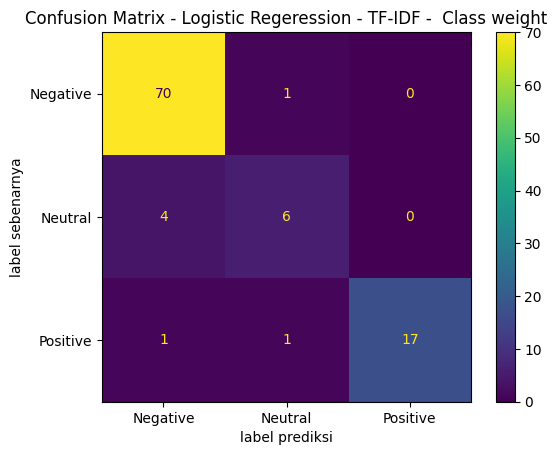

In [37]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic Regeression - TF-IDF -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [38]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9333    0.9859    0.9589        71
     Neutral     0.7500    0.6000    0.6667        10
    Positive     1.0000    0.8947    0.9444        19

    accuracy                         0.9300       100
   macro avg     0.8944    0.8269    0.8567       100
weighted avg     0.9277    0.9300    0.9269       100



<h3>IndoBERT Embedding Vectorization</h3>

In [39]:
#Catboost
import shutil

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    class_weights=class_weights,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train_bert,y_train,eval_set=(X_val_bert, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test_bert).ravel()

0:	learn: 1.0547860	test: 1.0695602	best: 1.0695602 (0)	total: 43.8ms	remaining: 21.9s
100:	learn: 0.1356505	test: 0.5333186	best: 0.5333186 (100)	total: 4.22s	remaining: 16.7s
200:	learn: 0.0590775	test: 0.5035250	best: 0.5032487 (195)	total: 8.23s	remaining: 12.2s
300:	learn: 0.0361665	test: 0.4984205	best: 0.4983073 (296)	total: 12.2s	remaining: 8.08s
bestTest = 0.4983072969
bestIteration = 296
Shrink model to first 297 iterations.


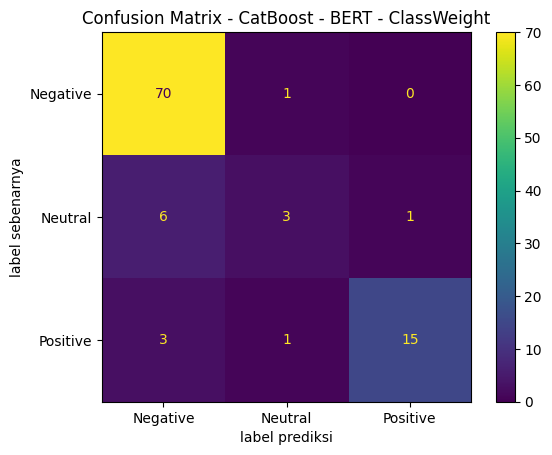

In [40]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - BERT - ClassWeight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [41]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8861    0.9859    0.9333        71
     Neutral     0.6000    0.3000    0.4000        10
    Positive     0.9375    0.7895    0.8571        19

    accuracy                         0.8800       100
   macro avg     0.8079    0.6918    0.7302       100
weighted avg     0.8672    0.8800    0.8655       100



In [42]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_bert, y_train)
y_pred = lr.predict(X_test_bert).ravel()

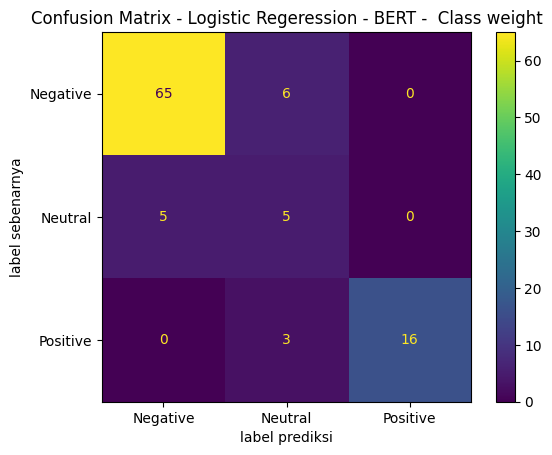

In [43]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic Regeression - BERT -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [44]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9286    0.9155    0.9220        71
     Neutral     0.3571    0.5000    0.4167        10
    Positive     1.0000    0.8421    0.9143        19

    accuracy                         0.8600       100
   macro avg     0.7619    0.7525    0.7510       100
weighted avg     0.8850    0.8600    0.8700       100



<h1>Modelling Without Class-Weight</h1>

<h3>TF-IDF</h3>

In [45]:
#Catboost

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train,y_train,eval_set=(X_val, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test).ravel()

0:	learn: 1.0446770	test: 1.0492952	best: 1.0492952 (0)	total: 10.5ms	remaining: 5.25s
100:	learn: 0.3311240	test: 0.4388230	best: 0.4386286 (99)	total: 859ms	remaining: 3.39s
200:	learn: 0.2656303	test: 0.4230134	best: 0.4220609 (184)	total: 1.71s	remaining: 2.54s
300:	learn: 0.2181888	test: 0.4071930	best: 0.4069727 (299)	total: 2.56s	remaining: 1.69s
400:	learn: 0.1876477	test: 0.3994266	best: 0.3987583 (392)	total: 3.41s	remaining: 841ms
499:	learn: 0.1668796	test: 0.3932674	best: 0.3930089 (488)	total: 4.24s	remaining: 0us
bestTest = 0.3930088679
bestIteration = 488
Shrink model to first 489 iterations.


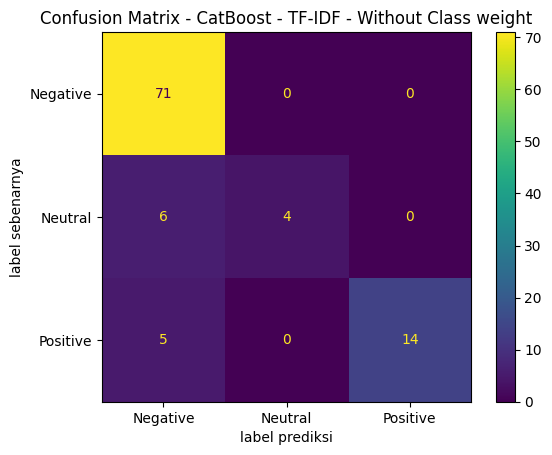

In [46]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - TF-IDF - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [47]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8659    1.0000    0.9281        71
     Neutral     1.0000    0.4000    0.5714        10
    Positive     1.0000    0.7368    0.8485        19

    accuracy                         0.8900       100
   macro avg     0.9553    0.7123    0.7827       100
weighted avg     0.9048    0.8900    0.8773       100



In [48]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test).ravel()

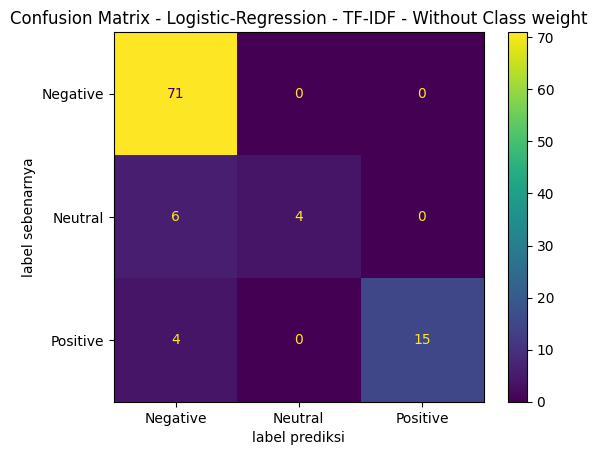

In [49]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic-Regression - TF-IDF - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [50]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8765    1.0000    0.9342        71
     Neutral     1.0000    0.4000    0.5714        10
    Positive     1.0000    0.7895    0.8824        19

    accuracy                         0.9000       100
   macro avg     0.9588    0.7298    0.7960       100
weighted avg     0.9123    0.9000    0.8881       100



<h3>IndoBERT Embedding Vectorization</h3>

In [51]:
#Catboost
import shutil

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train_bert,y_train,eval_set=(X_val_bert, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test_bert).ravel()

0:	learn: 1.0398341	test: 1.0440056	best: 1.0440056 (0)	total: 58.7ms	remaining: 29.3s
100:	learn: 0.1137986	test: 0.2757068	best: 0.2757068 (100)	total: 3.72s	remaining: 14.7s
200:	learn: 0.0520091	test: 0.2461901	best: 0.2461901 (200)	total: 7.03s	remaining: 10.5s
300:	learn: 0.0326780	test: 0.2369950	best: 0.2369681 (299)	total: 10.3s	remaining: 6.8s
400:	learn: 0.0231810	test: 0.2343614	best: 0.2341366 (382)	total: 13.6s	remaining: 3.36s
bestTest = 0.234125185
bestIteration = 405
Shrink model to first 406 iterations.


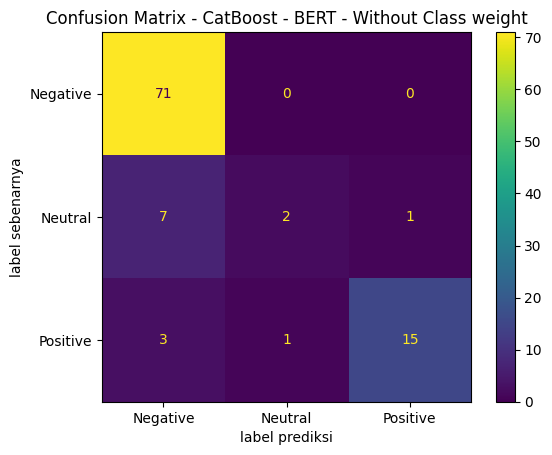

In [52]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - BERT - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [53]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8765    1.0000    0.9342        71
     Neutral     0.6667    0.2000    0.3077        10
    Positive     0.9375    0.7895    0.8571        19

    accuracy                         0.8800       100
   macro avg     0.8269    0.6632    0.6997       100
weighted avg     0.8671    0.8800    0.8569       100



In [54]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_bert, y_train)
y_pred = lr.predict(X_test_bert).ravel()

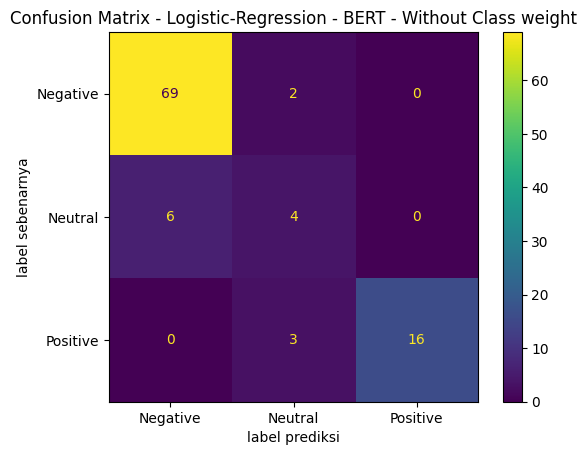

In [55]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic-Regression - BERT - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [56]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9200    0.9718    0.9452        71
     Neutral     0.4444    0.4000    0.4211        10
    Positive     1.0000    0.8421    0.9143        19

    accuracy                         0.8900       100
   macro avg     0.7881    0.7380    0.7602       100
weighted avg     0.8876    0.8900    0.8869       100



<h1>WordCloud Analysis</h1>

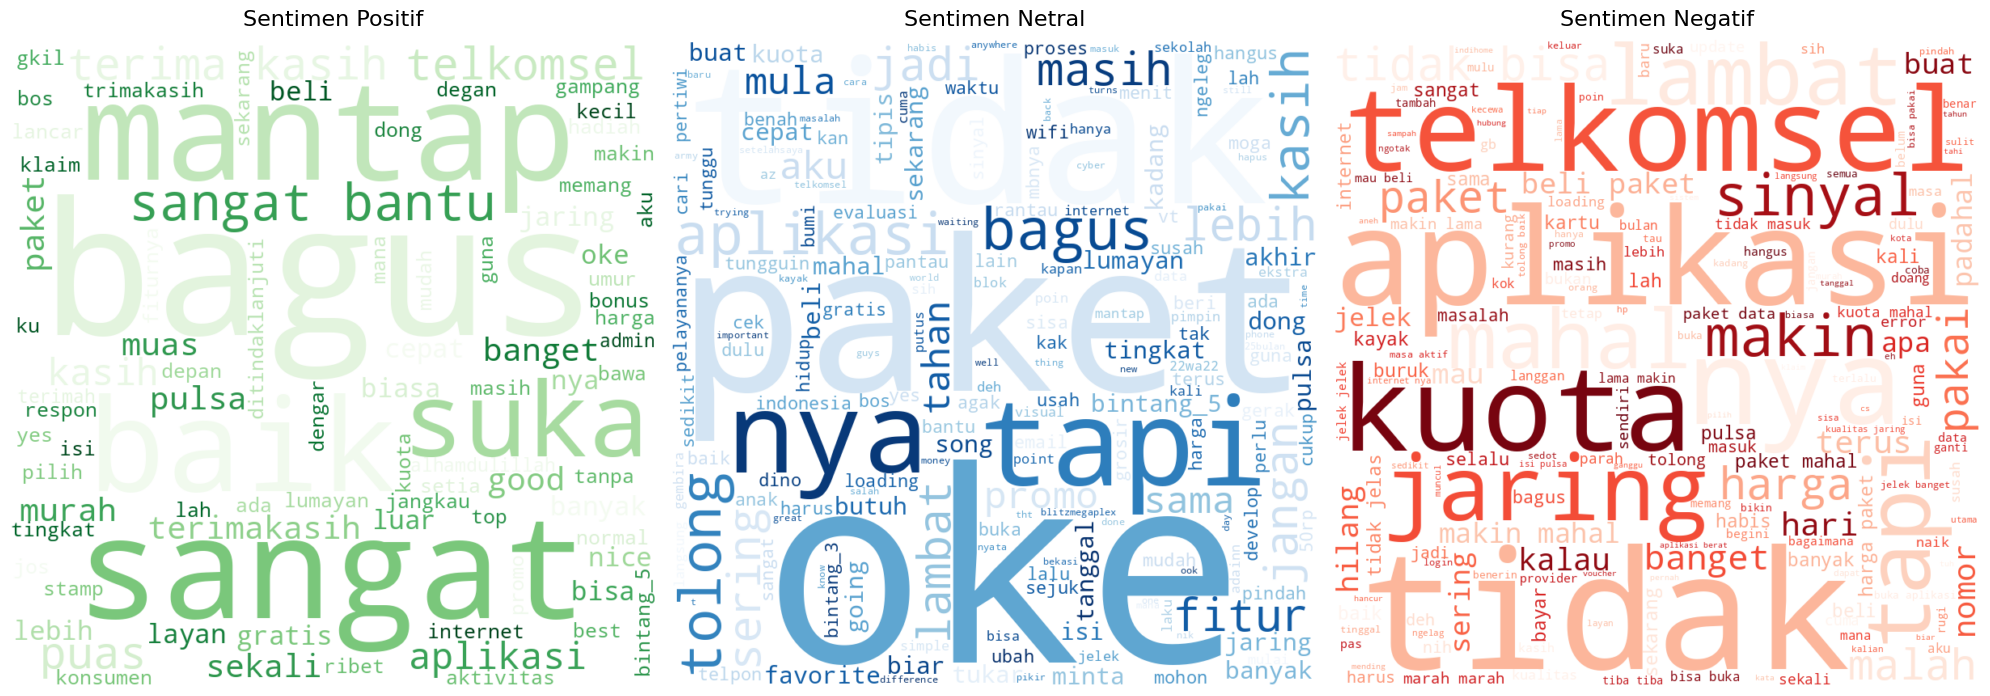

In [58]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

ulasan_positif = " ".join(target[target["target"] == 1]["ulasan_clean"])
ulasan_negatif = " ".join(target[target["target"] == -1]["ulasan_clean"])
ulasan_netral = " ".join(target[target["target"] == 0]["ulasan_clean"])

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

if ulasan_positif.strip():
    wc_pos = WordCloud(width=800, height=800, background_color='white', colormap='Greens', min_font_size=10).generate(ulasan_positif)
    axes[0].imshow(wc_pos, interpolation='bilinear')
    axes[0].set_title("Sentimen Positif", fontsize=16, pad=10)
else:
    axes[0].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[0].axis("off")

if ulasan_netral.strip():
    wc_neu = WordCloud(width=800, height=800, background_color='white', colormap='Blues', min_font_size=10).generate(ulasan_netral)
    axes[1].imshow(wc_neu, interpolation='bilinear')
    axes[1].set_title("Sentimen Netral", fontsize=16, pad=10)
else:
    axes[1].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[1].axis("off")

if ulasan_negatif.strip():
    wc_neg = WordCloud(width=800, height=800, background_color='white', colormap='Reds', min_font_size=10).generate(ulasan_negatif)
    axes[2].imshow(wc_neg, interpolation='bilinear')
    axes[2].set_title("Sentimen Negatif", fontsize=16, pad=10)
else:
    axes[2].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()